In [1]:
import pandas as pd
import numpy as nps

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
import os

print("Current folder:")
print(os.getcwd())

print("\nFiles/folders here:")
print(os.listdir())

Current folder:
c:\Users\ADMIN\OneDrive\Desktop\Ecommerce_AI_ML_Project\notebook

Files/folders here:
['01_data_understanding.ipynb']


In [3]:
import pandas as pd
import numpy as np

file_path = "../data/online_retail_II.xlsx"

excel_file = pd.ExcelFile(file_path)

print("Excel file loaded successfully!")
print("Available sheets:")
print(excel_file.sheet_names)

Excel file loaded successfully!
Available sheets:
['Year 2009-2010', 'Year 2010-2011']


In [4]:
# Load both sheets

df_2009_2010 = pd.read_excel(
    file_path,
    sheet_name="Year 2009-2010",
    engine="openpyxl"
)

df_2010_2011 = pd.read_excel(
    file_path,
    sheet_name="Year 2010-2011",
    engine="openpyxl"
)

print("2009-2010 rows:", len(df_2009_2010))
print("2010-2011 rows:", len(df_2010_2011))

2009-2010 rows: 525461
2010-2011 rows: 541910


In [5]:
# Combine both years into one master dataset

df = pd.concat([df_2009_2010, df_2010_2011], ignore_index=True)

print("Total rows:", len(df))
print("Total columns:", len(df.columns))

print("\nColumn names:")
print(df.columns.tolist())

Total rows: 1067371
Total columns: 8

Column names:
['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']


In [6]:
# Display the first 5 rows of the dataset

df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [7]:
# Check the data types of all columns

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[ns]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 65.1+ MB


In [8]:
# Check the number of missing values in each column

df.isnull().sum()

Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64

In [9]:
# Check for duplicate rows

duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 34335


In [10]:
# Look at some duplicate rows

duplicates = df[df.duplicated(keep=False)]

duplicates.head(20)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
362,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
363,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
365,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
367,489517,22319,HAIRCLIPS FORTIES FABRIC ASSORTED,12,2009-12-01 11:34:00,0.65,16329.0,United Kingdom
368,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,2009-12-01 11:34:00,0.85,16329.0,United Kingdom
371,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
379,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.0,United Kingdom
383,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,2009-12-01 11:34:00,0.85,16329.0,United Kingdom
384,489517,22319,HAIRCLIPS FORTIES FABRIC ASSORTED,12,2009-12-01 11:34:00,0.65,16329.0,United Kingdom
385,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom


In [11]:
# Count duplicate rows by invoice

duplicate_invoices = duplicates["Invoice"].value_counts()

print("Number of invoices containing duplicate rows:",
      duplicate_invoices.shape[0])

print("\nTop invoices with duplicate rows:")
print(duplicate_invoices.head(10))

Number of invoices containing duplicate rows: 5391

Top invoices with duplicate rows:
Invoice
537434    1350
538071    1304
537638    1202
537237    1194
536876    1186
536592    1184
537823    1182
537240    1136
537666    1072
536544    1054
Name: count, dtype: int64


In [12]:
# Inspect invoice 537434

invoice_537434 = df[df["Invoice"] == 537434]

print("Number of rows in invoice 537434:", len(invoice_537434))

invoice_537434.head(20)

Number of rows in invoice 537434: 1350


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
516208,537434,20685,DOORMAT RED RETROSPOT,1,2010-12-06 16:57:00,14.43,NaN,United Kingdom
516209,537434,20699,MOUSEY LONG LEGS SOFT TOY,1,2010-12-06 16:57:00,5.06,NaN,United Kingdom
516210,537434,20713,JUMBO BAG OWLS,1,2010-12-06 16:57:00,4.21,NaN,United Kingdom
516211,537434,20719,WOODLAND CHARLOTTE BAG,3,2010-12-06 16:57:00,1.66,NaN,United Kingdom
516212,537434,20725,LUNCH BAG RED RETROSPOT,4,2010-12-06 16:57:00,4.21,NaN,United Kingdom
516213,537434,20728,LUNCH BAG CARS BLUE,1,2010-12-06 16:57:00,4.21,NaN,United Kingdom
516214,537434,20733,GOLD MINI TAPE MEASURE,3,2010-12-06 16:57:00,0.85,NaN,United Kingdom
516215,537434,20735,BLACK MINI TAPE MEASURE,1,2010-12-06 16:57:00,0.85,NaN,United Kingdom
516216,537434,20752,BLUE POLKADOT WASHING UP GLOVES,1,2010-12-06 16:57:00,4.21,NaN,United Kingdom
516217,537434,20754,RETROSPOT RED WASHING UP GLOVES,1,2010-12-06 16:57:00,4.21,NaN,United Kingdom


In [13]:
# Check how many completely identical rows exist in this invoice

print(
    "Exact duplicate rows in invoice 537434:",
    invoice_537434.duplicated().sum()
)

Exact duplicate rows in invoice 537434: 675


In [14]:
# Remove exact duplicate rows

original_rows = len(df)

df_clean = df.drop_duplicates().copy()

cleaned_rows = len(df_clean)

print("Original rows:", original_rows)
print("Rows after removing exact duplicates:", cleaned_rows)
print("Duplicate rows removed:", original_rows - cleaned_rows)

Original rows: 1067371
Rows after removing exact duplicates: 1033036
Duplicate rows removed: 34335


In [15]:
# Check cancelled invoices

cancelled_mask = df_clean["Invoice"].astype(str).str.startswith("C")

print("Cancelled transaction rows:", cancelled_mask.sum())
print("Normal transaction rows:", (~cancelled_mask).sum())

Cancelled transaction rows: 19104
Normal transaction rows: 1013932


In [16]:
# Check the quantity values for cancelled transactions

cancelled_data = df_clean[cancelled_mask]

print("Cancelled transactions with negative quantity:")
print((cancelled_data["Quantity"] < 0).sum())

print("\nCancelled transactions with positive quantity:")
print((cancelled_data["Quantity"] > 0).sum())

Cancelled transactions with negative quantity:
19103

Cancelled transactions with positive quantity:
1


In [17]:
# Check negative quantities in the complete dataset

print("Total rows with negative quantity:",
      (df_clean["Quantity"] < 0).sum())

print("Total rows with zero quantity:",
      (df_clean["Quantity"] == 0).sum())

print("Total rows with positive quantity:",
      (df_clean["Quantity"] > 0).sum())

Total rows with negative quantity: 22496
Total rows with zero quantity: 0
Total rows with positive quantity: 1010540


In [18]:
# Create completed sales transactions

sales_df = df_clean[df_clean["Quantity"] > 0].copy()

print("Total completed sales transactions:", len(sales_df))
print("Negative transactions excluded:", len(df_clean) - len(sales_df))

Total completed sales transactions: 1010540
Negative transactions excluded: 22496


In [19]:
# Calculate revenue for each transaction

sales_df["Revenue"] = sales_df["Quantity"] * sales_df["Price"]

print("Revenue column created successfully!")

sales_df[["Invoice", "StockCode", "Quantity", "Price", "Revenue"]].head()

Revenue column created successfully!


,Invoice,StockCode,Quantity,Price,Revenue
0,489434,85048,12,6.95,83.4
1,489434,79323P,12,6.75,81.0
2,489434,79323W,12,6.75,81.0
3,489434,22041,48,2.10,100.8
4,489434,21232,24,1.25,30.0


In [20]:
# Check the basic structure of our sales dataset

print("Rows:", len(sales_df))
print("Columns:", len(sales_df.columns))

print("\nColumn names:")
print(sales_df.columns.tolist())

Rows: 1010540
Columns: 9

Column names:
['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country', 'Revenue']


In [21]:
# Check missing values in the sales dataset

missing_values = sales_df.isnull().sum()

print(missing_values)

Invoice             0
StockCode           0
Description      1642
Quantity            0
InvoiceDate         0
Price               0
Customer ID    231045
Country             0
Revenue             0
dtype: int64


In [22]:
# Calculate missing Customer ID percentage

missing_customer = sales_df["Customer ID"].isnull().sum()
total_sales = len(sales_df)

missing_percentage = (missing_customer / total_sales) * 100

print("Missing Customer IDs:", missing_customer)
print("Total sales transactions:", total_sales)
print(f"Missing Customer ID percentage: {missing_percentage:.2f}%")

Missing Customer IDs: 231045
Total sales transactions: 1010540
Missing Customer ID percentage: 22.86%


In [23]:
# Create dataset for customer-level analysis

customer_df = sales_df[sales_df["Customer ID"].notnull()].copy()

print("Customer-level transactions:", len(customer_df))
print("Unique customers:", customer_df["Customer ID"].nunique())

Customer-level transactions: 779495
Unique customers: 5881


In [24]:
# Calculate basic business KPIs

total_revenue = sales_df["Revenue"].sum()
total_quantity = sales_df["Quantity"].sum()
total_orders = sales_df["Invoice"].nunique()
total_products = sales_df["StockCode"].nunique()
total_countries = sales_df["Country"].nunique()
total_customers = customer_df["Customer ID"].nunique()

average_order_value = total_revenue / total_orders

print("========== E-COMMERCE BUSINESS KPIs ==========")
print(f"Total Revenue: £{total_revenue:,.2f}")
print(f"Total Quantity Sold: {total_quantity:,}")
print(f"Total Orders: {total_orders:,}")
print(f"Total Unique Products: {total_products:,}")
print(f"Total Countries: {total_countries:,}")
print(f"Total Customers: {total_customers:,}")
print(f"Average Order Value: £{average_order_value:,.2f}")

========== E-COMMERCE BUSINESS KPIs ==========
Total Revenue: £20,317,957.88
Total Quantity Sold: 11,455,913
Total Orders: 41,944
Total Unique Products: 4,985
Total Countries: 43
Total Customers: 5,881
Average Order Value: £484.41


In [25]:
# Top 10 countries by revenue

top_countries = (
    sales_df.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 Countries by Revenue:")
print(top_countries)

Top 10 Countries by Revenue:
Country
United Kingdom    1.725189e+07
EIRE              6.587673e+05
Netherlands       5.540381e+05
Germany           4.250197e+05
France            3.504561e+05
Australia         1.692835e+05
Spain             1.083325e+05
Switzerland       1.006856e+05
Sweden            9.186982e+04
Denmark           6.858069e+04
Name: Revenue, dtype: float64


In [26]:
# Top 10 products by revenue

top_products = (
    sales_df.groupby(["StockCode", "Description"])["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 Products by Revenue:")
print(top_products)

Top 10 Products by Revenue:
StockCode  Description                       
M          Manual                                339599.81
22423      REGENCY CAKESTAND 3 TIER              330590.32
DOT        DOTCOM POSTAGE                        309854.11
85123A     WHITE HANGING HEART T-LIGHT HOLDER    257546.20
23843      PAPER CRAFT , LITTLE BIRDIE           168469.60
47566      PARTY BUNTING                         148318.28
85099B     JUMBO BAG RED RETROSPOT               145961.83
84879      ASSORTED COLOUR BIRD ORNAMENT         129324.49
POST       POSTAGE                               125682.42
22086      PAPER CHAIN KIT 50'S CHRISTMAS        117760.29
Name: Revenue, dtype: float64


In [27]:
# Prepare invoice date

sales_df["InvoiceDate"] = pd.to_datetime(sales_df["InvoiceDate"])

# Create monthly revenue

monthly_revenue = (
    sales_df
    .set_index("InvoiceDate")
    .resample("M")["Revenue"]
    .sum()
)

print("Monthly revenue:")
print(monthly_revenue)

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_14516\904525942.py:10: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  .resample("M")["Revenue"]


Monthly revenue:
InvoiceDate
2009-12-31     822483.950
2010-01-31     651155.112
2010-02-28     551878.296
2010-03-31     830915.261
2010-04-30     625280.892
2010-05-31     657705.500
2010-06-30     749537.310
2010-07-31     604778.480
2010-08-31     695251.910
2010-09-30     921696.991
2010-10-31    1122976.350
2010-11-30    1464293.142
2010-12-31     821452.730
2011-01-31     689811.610
2011-02-28     522545.560
2011-03-31     716215.260
2011-04-30     536968.491
2011-05-31     769296.610
2011-06-30     760547.010
2011-07-31     718076.121
2011-08-31     735717.260
2011-09-30    1056435.192
2011-10-31    1151263.730
2011-11-30    1503866.780
2011-12-31     637808.330
Freq: ME, Name: Revenue, dtype: float64


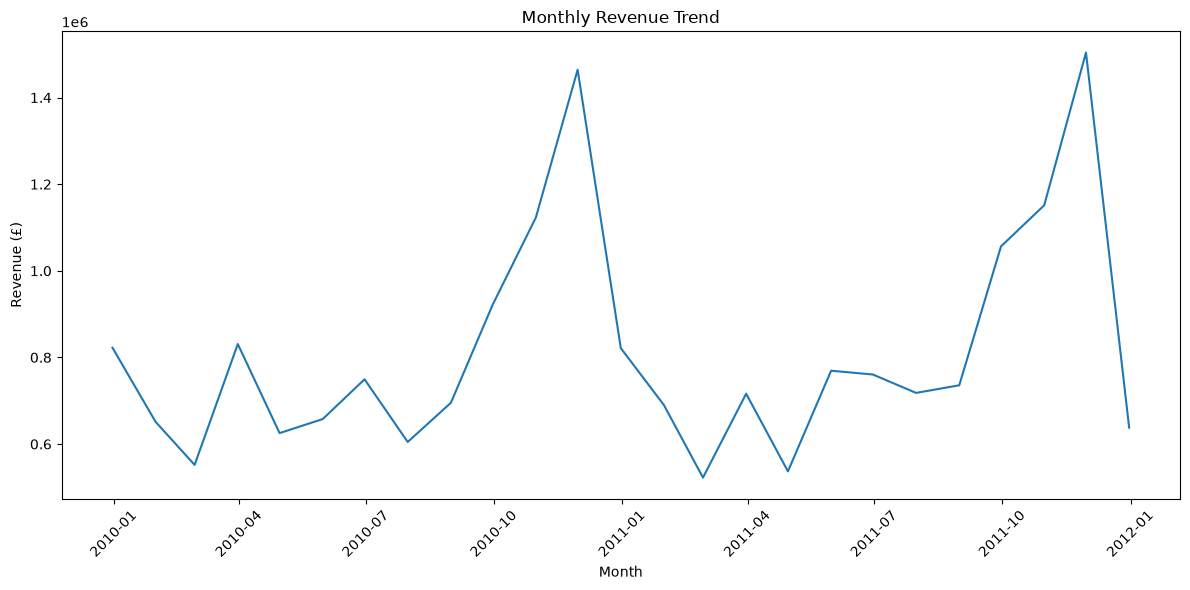

In [28]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(monthly_revenue.index, monthly_revenue.values)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [29]:
import matplotlib

print("Matplotlib version:", matplotlib.__version__)

Matplotlib version: 3.11.1


In [30]:
import matplotlib.pyplot as plt

print("Matplotlib is working!")

Matplotlib is working!


In [31]:
print("sales_df rows:", len(sales_df))
print("customer_df rows:", len(customer_df))


sales_df rows: 1010540
customer_df rows: 779495


In [32]:
import pandas as pd
import numpy as np

# Excel file location
file_path = "../data/online_retail_II.xlsx"

# Load both sheets
df_2009_2010 = pd.read_excel(
    file_path,
    sheet_name="Year 2009-2010",
    engine="openpyxl"
)

df_2010_2011 = pd.read_excel(
    file_path,
    sheet_name="Year 2010-2011",
    engine="openpyxl"
)

# Combine both years
df = pd.concat(
    [df_2009_2010, df_2010_2011],
    ignore_index=True
)

print("Original rows:", len(df))

# Remove exact duplicate rows
df_clean = df.drop_duplicates().copy()

print("Cleaned rows:", len(df_clean))
print("Duplicates removed:", len(df) - len(df_clean))

# Keep completed/positive sales
sales_df = df_clean[df_clean["Quantity"] > 0].copy()

# Calculate revenue
sales_df["Revenue"] = sales_df["Quantity"] * sales_df["Price"]

# Customer-level dataset
customer_df = sales_df[
    sales_df["Customer ID"].notnull()
].copy()

print("\n========== DATA RESTORED ==========")
print("Sales transactions:", len(sales_df))
print("Customer transactions:", len(customer_df))
print("Unique customers:", customer_df["Customer ID"].nunique())
print("Revenue column:", "Revenue" in sales_df.columns)

Original rows: 1067371
Cleaned rows: 1033036
Duplicates removed: 34335

========== DATA RESTORED ==========
Sales transactions: 1010540
Customer transactions: 779495
Unique customers: 5881
Revenue column: True


In [33]:
print("sales_df:", len(sales_df))
print("customer_df:", len(customer_df))
print("Revenue:", sales_df["Revenue"].sum())

sales_df: 1010540
customer_df: 779495
Revenue: 20317957.878000002


In [34]:
import matplotlib.pyplot as plt

print("Matplotlib is working!")

Matplotlib is working!


In [35]:
# Convert InvoiceDate to datetime

sales_df["InvoiceDate"] = pd.to_datetime(sales_df["InvoiceDate"])

print("InvoiceDate converted successfully!")
print(sales_df["InvoiceDate"].min())
print(sales_df["InvoiceDate"].max())

InvoiceDate converted successfully!
2009-12-01 07:45:00
2011-12-09 12:50:00


In [36]:
# Calculate monthly revenue

monthly_revenue = (
    sales_df
    .set_index("InvoiceDate")
    .resample("ME")["Revenue"]
    .sum()
)

print("Monthly Revenue:")
print(monthly_revenue)

Monthly Revenue:
InvoiceDate
2009-12-31     822483.950
2010-01-31     651155.112
2010-02-28     551878.296
2010-03-31     830915.261
2010-04-30     625280.892
2010-05-31     657705.500
2010-06-30     749537.310
2010-07-31     604778.480
2010-08-31     695251.910
2010-09-30     921696.991
2010-10-31    1122976.350
2010-11-30    1464293.142
2010-12-31     821452.730
2011-01-31     689811.610
2011-02-28     522545.560
2011-03-31     716215.260
2011-04-30     536968.491
2011-05-31     769296.610
2011-06-30     760547.010
2011-07-31     718076.121
2011-08-31     735717.260
2011-09-30    1056435.192
2011-10-31    1151263.730
2011-11-30    1503866.780
2011-12-31     637808.330
Freq: ME, Name: Revenue, dtype: float64


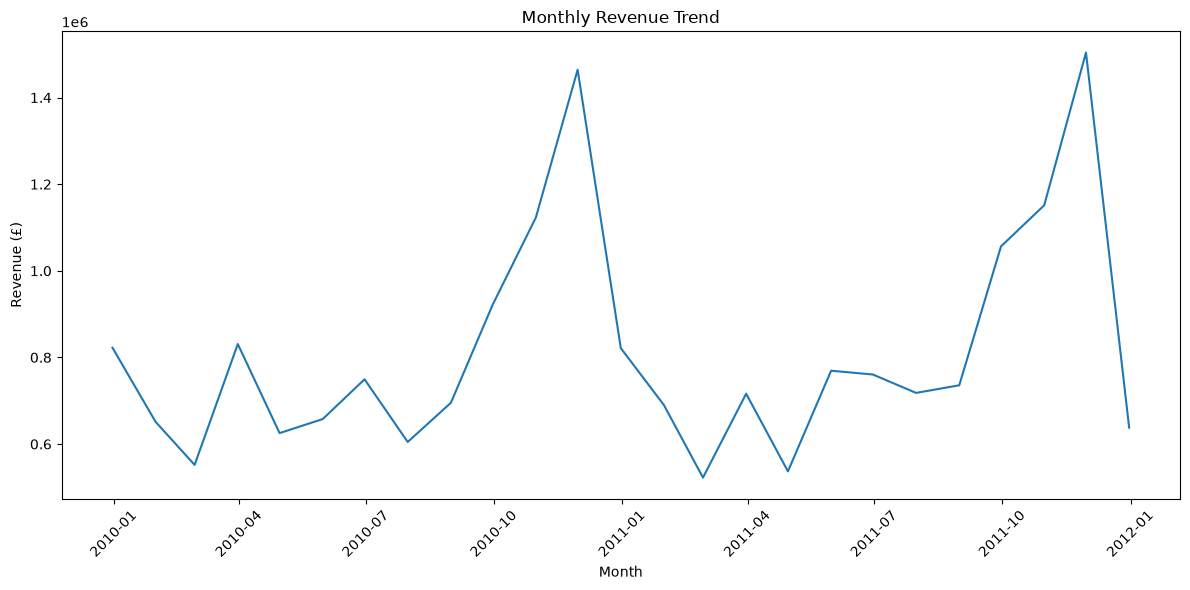

In [37]:
# Monthly Revenue Trend

plt.figure(figsize=(12, 6))

plt.plot(monthly_revenue.index, monthly_revenue.values)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [38]:
# Calculate monthly order count

monthly_orders = (
    sales_df
    .set_index("InvoiceDate")["Invoice"]
    .resample("ME")
    .nunique()
)

print("Monthly Orders:")
print(monthly_orders)

Monthly Orders:
InvoiceDate
2009-12-31    1839
2010-01-31    1205
2010-02-28    1282
2010-03-31    1770
2010-04-30    1513
2010-05-31    1642
2010-06-30    1719
2010-07-31    1585
2010-08-31    1511
2010-09-30    1911
2010-10-31    2371
2010-11-30    2868
2010-12-31    1629
2011-01-31    1120
2011-02-28    1126
2011-03-31    1531
2011-04-30    1318
2011-05-31    1731
2011-06-30    1576
2011-07-31    1540
2011-08-31    1409
2011-09-30    1896
2011-10-31    2129
2011-11-30    2884
2011-12-31     839
Freq: ME, Name: Invoice, dtype: int64


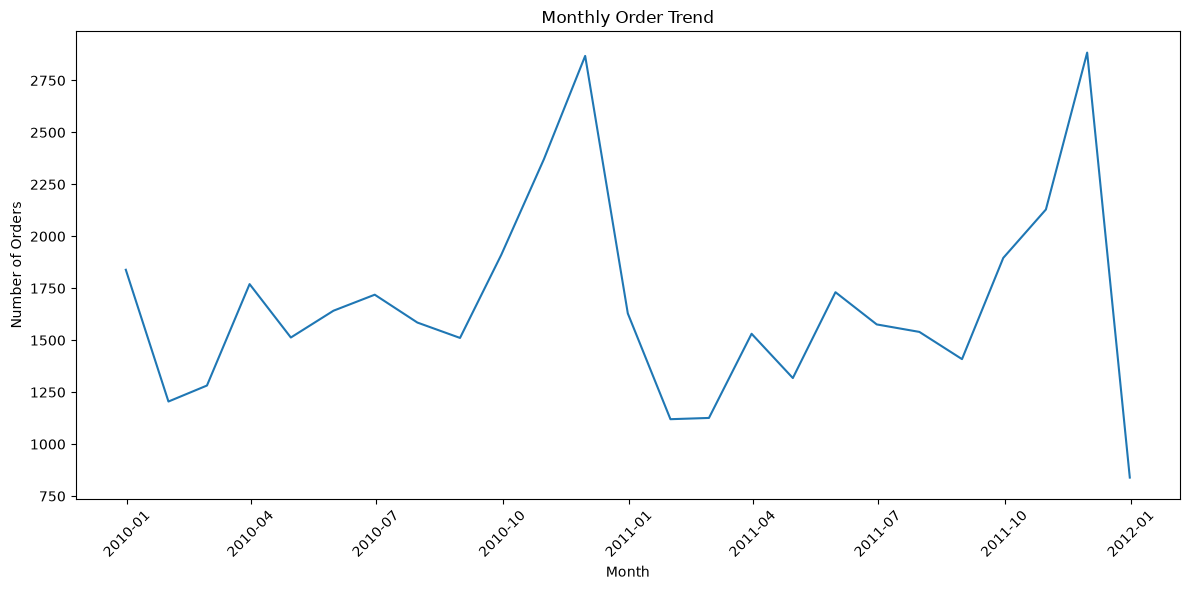

In [39]:
# Monthly Order Trend

plt.figure(figsize=(12, 6))

plt.plot(monthly_orders.index, monthly_orders.values)

plt.title("Monthly Order Trend")
plt.xlabel("Month")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [40]:
# Calculate Monthly Average Order Value

monthly_aov = monthly_revenue / monthly_orders

print("Monthly Average Order Value:")
print(monthly_aov)

Monthly Average Order Value:
InvoiceDate
2009-12-31    447.245215
2010-01-31    540.377686
2010-02-28    430.482290
2010-03-31    469.443650
2010-04-30    413.272235
2010-05-31    400.551462
2010-06-30    436.031012
2010-07-31    381.563710
2010-08-31    460.127009
2010-09-30    482.311351
2010-10-31    473.629840
2010-11-30    510.562462
2010-12-31    504.268097
2011-01-31    615.903223
2011-02-28    464.072433
2011-03-31    467.808792
2011-04-30    407.411602
2011-05-31    444.423229
2011-06-30    482.580590
2011-07-31    466.283195
2011-08-31    522.155614
2011-09-30    557.191557
2011-10-31    540.753279
2011-11-30    521.451727
2011-12-31    760.200632
Freq: ME, dtype: float64


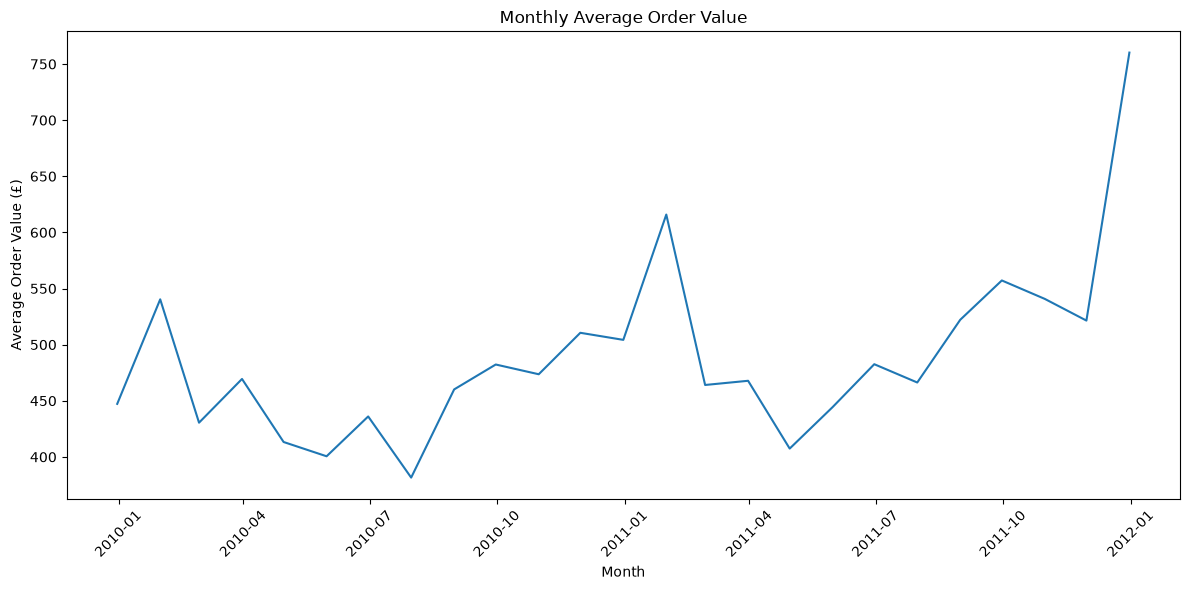

In [41]:
# Monthly Average Order Value Trend

plt.figure(figsize=(12, 6))

plt.plot(monthly_aov.index, monthly_aov.values)

plt.title("Monthly Average Order Value")
plt.xlabel("Month")
plt.ylabel("Average Order Value (£)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [42]:
# Find the latest transaction date

latest_date = customer_df["InvoiceDate"].max()

analysis_date = latest_date + pd.Timedelta(days=1)

print("Latest transaction date:", latest_date)
print("RFM analysis date:", analysis_date)

Latest transaction date: 2011-12-09 12:50:00
RFM analysis date: 2011-12-10 12:50:00


In [43]:
# Calculate RFM metrics for each customer

rfm = customer_df.groupby("Customer ID").agg(
    Recency=("InvoiceDate", lambda x: (analysis_date - x.max()).days),
    Frequency=("Invoice", "nunique"),
    Monetary=("Revenue", "sum")
).reset_index()

print("RFM dataset created successfully!")
print("Number of customers:", len(rfm))

rfm.head()

RFM dataset created successfully!
Number of customers: 5881


,Customer ID,Recency,Frequency,Monetary
0,12346.0,326,12,77556.46
1,12347.0,2,8,4921.53
2,12348.0,75,5,2019.40
3,12349.0,19,4,4428.69
4,12350.0,310,1,334.40


In [44]:
# Check RFM statistics

print("RFM Statistics:")
print(rfm[["Recency", "Frequency", "Monetary"]].describe())

RFM Statistics:
           Recency    Frequency       Monetary
count  5881.000000  5881.000000    5881.000000
mean    201.457745     6.287196    2954.396237
std     209.474135    13.012879   14437.322635
min       1.000000     1.000000       0.000000
25%      26.000000     1.000000     341.900000
50%      96.000000     3.000000     865.600000
75%     380.000000     7.000000    2247.720000
max     739.000000   398.000000  580987.040000


In [45]:
# Check for invalid RFM values

print("Negative Recency:", (rfm["Recency"] < 0).sum())
print("Zero Frequency:", (rfm["Frequency"] == 0).sum())
print("Zero Monetary:", (rfm["Monetary"] == 0).sum())

Negative Recency: 0
Zero Frequency: 0
Zero Monetary: 3


In [46]:
from sklearn.preprocessing import StandardScaler

# Select RFM features
rfm_features = rfm[["Recency", "Frequency", "Monetary"]].copy()

# Log transformation to reduce the effect of extreme values
rfm_log = np.log1p(rfm_features)

# Standardize the features
scaler = StandardScaler()

rfm_scaled = scaler.fit_transform(rfm_log)

print("RFM data prepared for clustering!")
print("Shape:", rfm_scaled.shape)

RFM data prepared for clustering!
Shape: (5881, 3)


In [47]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Test different numbers of clusters
k_values = range(2, 9)

inertia_values = []
silhouette_values = []

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    labels = kmeans.fit_predict(rfm_scaled)
    
    inertia_values.append(kmeans.inertia_)
    silhouette_values.append(
        silhouette_score(rfm_scaled, labels)
    )

print("K values:", list(k_values))
print("Inertia:", inertia_values)
print("Silhouette scores:", silhouette_values)

K values: [2, 3, 4, 5, 6, 7, 8]
Inertia: [8615.202802890184, 6383.772504798562, 4951.565473597246, 4130.504874034192, 3586.7635315286175, 3223.155760495464, 2924.88176744424]
Silhouette scores: [0.4384307118444161, 0.34681132082336386, 0.36469806146279604, 0.34235548716042785, 0.3326581124209852, 0.2963720327054177, 0.2956266974744919]


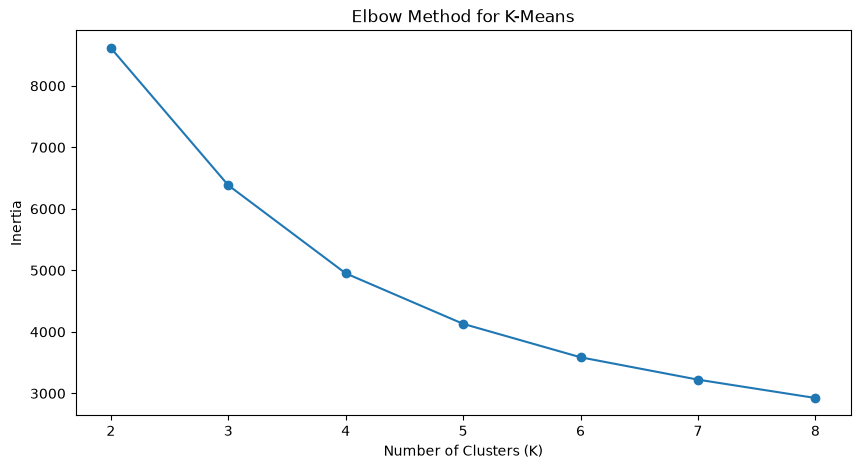

In [48]:
plt.figure(figsize=(10, 5))

plt.plot(list(k_values), inertia_values, marker="o")

plt.title("Elbow Method for K-Means")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(list(k_values))

plt.show()

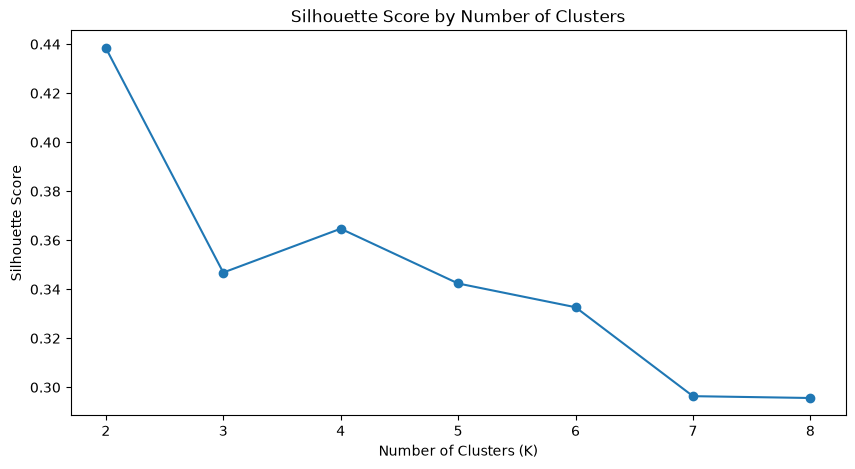

In [49]:
plt.figure(figsize=(10, 5))

plt.plot(list(k_values), silhouette_values, marker="o")

plt.title("Silhouette Score by Number of Clusters")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.xticks(list(k_values))

plt.show()

In [50]:
# Final K-Means model with K = 2

kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

rfm["Cluster"] = kmeans.fit_predict(rfm_scaled)

print("K-Means clustering completed!")
print("\nCustomers in each cluster:")
print(rfm["Cluster"].value_counts().sort_index())

K-Means clustering completed!

Customers in each cluster:
Cluster
0    2314
1    3567
Name: count, dtype: int64


In [51]:
# Compare the average RFM values of each cluster

cluster_summary = rfm.groupby("Cluster")[
    ["Recency", "Frequency", "Monetary"]
].mean().round(2)

print(cluster_summary)

         Recency  Frequency  Monetary
Cluster                              
0          50.13      12.74   6555.46
1         299.63       2.10    618.30


In [52]:
# Create descriptive customer segment names

rfm["Segment"] = rfm["Cluster"].map({
    0: "High-Value Active Customers",
    1: "Low-Engagement Customers"
})

print(rfm[["Customer ID", "Recency", "Frequency", "Monetary", "Cluster", "Segment"]].head())

   Customer ID  Recency  Frequency  Monetary  Cluster  \
0      12346.0      326         12  77556.46        0   
1      12347.0        2          8   4921.53        0   
2      12348.0       75          5   2019.40        0   
3      12349.0       19          4   4428.69        0   
4      12350.0      310          1    334.40        1   

                       Segment  
0  High-Value Active Customers  
1  High-Value Active Customers  
2  High-Value Active Customers  
3  High-Value Active Customers  
4     Low-Engagement Customers  


In [53]:
print("\nCustomer Segment Distribution:")
print(rfm["Segment"].value_counts())


Customer Segment Distribution:
Segment
Low-Engagement Customers       3567
High-Value Active Customers    2314
Name: count, dtype: int64


In [54]:
# Save customer segmentation results

rfm.to_csv("../models/customer_segments.csv", index=False)

print("Customer segmentation saved successfully!")

Customer segmentation saved successfully!


In [55]:
import os

print("Current folder:")
print(os.getcwd())

print("\nFolders/files here:")
print(os.listdir())

Current folder:
c:\Users\ADMIN\OneDrive\Desktop\Ecommerce_AI_ML_Project\notebook

Folders/files here:
['01_data_understanding.ipynb']


In [56]:
import os

models_path = "../models"

os.makedirs(models_path, exist_ok=True)

print("Models folder created/verified!")
print(os.path.abspath(models_path))

Models folder created/verified!
c:\Users\ADMIN\OneDrive\Desktop\Ecommerce_AI_ML_Project\models


In [57]:
import os

models_path = "../models"

print("Path:", os.path.abspath(models_path))
print("Exists:", os.path.exists(models_path))
print("Is folder:", os.path.isdir(models_path))
print("Is file:", os.path.isfile(models_path))

Path: c:\Users\ADMIN\OneDrive\Desktop\Ecommerce_AI_ML_Project\models
Exists: True
Is folder: True
Is file: False


In [58]:
import os

models_path = "../models"

print("File size:", os.path.getsize(models_path), "bytes")

File size: 4096 bytes


In [59]:
# Save customer segmentation results

import os

models_path = "../models"

print("Models folder exists:", os.path.exists(models_path))
print("Is folder:", os.path.isdir(models_path))

Models folder exists: True
Is folder: True


In [60]:
rfm.to_csv("../models/customer_segments.csv", index=False)

print("Customer segmentation saved successfully!")
print("File: models/customer_segments.csv")

Customer segmentation saved successfully!
File: models/customer_segments.csv


In [61]:
# ==========================================
# ML MODEL - CUSTOMER SPENDING PREDICTION
# ==========================================

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Features
X = rfm[["Recency", "Frequency"]]

# Target
y = rfm["Monetary"]

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 4704
Testing samples: 1177


In [62]:
# ==========================================
# TRAIN RANDOM FOREST REGRESSION MODEL
# ==========================================

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Create model
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train
rf_model.fit(X_train, y_train)

# Predictions
y_pred = rf_model.predict(X_test)

# Evaluation
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("========== MODEL PERFORMANCE ==========")
print(f"MAE  : £{mae:,.2f}")
print(f"RMSE : £{rmse:,.2f}")
print(f"R² Score: {r2:.4f}")

========== MODEL PERFORMANCE ==========
MAE  : £1,809.91
RMSE : £10,962.68
R² Score: 0.6226


In [63]:
# ==========================================
# SAVE TRAINED MODEL
# ==========================================

import joblib
import os

# Save model
model_path = "../models/customer_spending_model.pkl"

joblib.dump(rf_model, model_path)

print("Model saved successfully!")
print("Saved at:", model_path)

Model saved successfully!
Saved at: ../models/customer_spending_model.pkl


In [64]:
# ==========================================
# TEST CUSTOMER SPENDING PREDICTION
# ==========================================

# Example customer:
# Recency = 30 days
# Frequency = 10 orders

sample_customer = np.array([[30, 10]])

predicted_spending = rf_model.predict(sample_customer)[0]

print("========== CUSTOMER SPENDING PREDICTION ==========")
print(f"Recency   : 30 days")
print(f"Frequency : 10 orders")
print(f"Predicted Spending: £{predicted_spending:,.2f}")

========== CUSTOMER SPENDING PREDICTION ==========
Recency   : 30 days
Frequency : 10 orders
Predicted Spending: £4,635.61


c:\Users\ADMIN\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(


In [65]:
# Clean prediction test using feature names

sample_customer = pd.DataFrame({
    "Recency": [30],
    "Frequency": [10]
})

predicted_spending = rf_model.predict(sample_customer)[0]

print("========== CUSTOMER SPENDING PREDICTION ==========")
print("Recency   : 30 days")
print("Frequency : 10 orders")
print(f"Predicted Spending: £{predicted_spending:,.2f}")

========== CUSTOMER SPENDING PREDICTION ==========
Recency   : 30 days
Frequency : 10 orders
Predicted Spending: £4,635.61


In [66]:
# ==========================================
# PRODUCT RECOMMENDATION SYSTEM
# ==========================================

# Keep only required columns
recommendation_df = sales_df[
    ["Invoice", "Description"]
].dropna().copy()

# Remove duplicate products within the same invoice
recommendation_df = recommendation_df.drop_duplicates()

print("Transactions available:", len(recommendation_df))
print("Unique products:", recommendation_df["Description"].nunique())

Transactions available: 997008
Unique products: 5469


In [67]:
from collections import defaultdict

# Create product-to-product co-purchase counts
product_pairs = defaultdict(int)

for invoice, group in recommendation_df.groupby("Invoice"):
    products = group["Description"].tolist()

    # Limit to unique products in each invoice
    products = list(set(products))

    for i in range(len(products)):
        for j in range(i + 1, len(products)):
            product_pairs[(products[i], products[j])] += 1
            product_pairs[(products[j], products[i])] += 1

print("Product pairs created:", len(product_pairs))

Product pairs created: 11812944


In [68]:
# ==========================================
# PRODUCT RECOMMENDATION SYSTEM
# ==========================================

recommendation_df = sales_df[
    ["Invoice", "Description"]
].dropna().drop_duplicates()

print("Recommendation data created successfully!")
print("Rows:", len(recommendation_df))
print("Unique products:", recommendation_df["Description"].nunique())

Recommendation data created successfully!
Rows: 997008
Unique products: 5469


In [69]:
# ==========================================
# PRODUCT RECOMMENDATION FUNCTION
# ==========================================

def recommend_products(product_name, top_n=5):

    recommendations = []

    for (product_a, product_b), count in product_pairs.items():

        if product_a.lower() == product_name.lower():
            recommendations.append((product_b, count))

    recommendations.sort(
        key=lambda x: x[1],
        reverse=True
    )

    return recommendations[:top_n]

print("Recommendation function created successfully!")

Recommendation function created successfully!


In [70]:
print(sales_df["Description"].dropna().unique()[:20])

['15CM CHRISTMAS GLASS BALL 20 LIGHTS' 'PINK CHERRY LIGHTS'
 ' WHITE CHERRY LIGHTS' 'RECORD FRAME 7" SINGLE SIZE '
 'STRAWBERRY CERAMIC TRINKET BOX' 'PINK DOUGHNUT TRINKET POT '
 'SAVE THE PLANET MUG' 'FANCY FONT HOME SWEET HOME DOORMAT' 'CAT BOWL '
 'DOG BOWL , CHASING BALL DESIGN' 'HEART MEASURING SPOONS LARGE'
 'LUNCHBOX WITH CUTLERY FAIRY CAKES ' 'DOOR MAT BLACK FLOCK '
 'LOVE BUILDING BLOCK WORD' 'HOME BUILDING BLOCK WORD'
 'ASSORTED COLOUR BIRD ORNAMENT' ' PEACE WOODEN BLOCK LETTERS'
 'CHRISTMAS CRAFT WHITE FAIRY ' 'HEART IVORY TRELLIS LARGE'
 'HEART FILIGREE DOVE LARGE']


In [71]:
# ==========================================
# TEST PRODUCT RECOMMENDATIONS
# ==========================================

product = "WHITE CHERRY LIGHTS"

recommendations = recommend_products(product, top_n=5)

print(f"Recommendations for: {product}")
print("-----------------------------------")

for i, (recommended_product, count) in enumerate(recommendations, start=1):
    print(f"{i}. {recommended_product}  |  Purchased together: {count} times")

Recommendations for: WHITE CHERRY LIGHTS
-----------------------------------
1. PINK CHERRY LIGHTS  |  Purchased together: 46 times
2. LIGHT PINK CHERRY LIGHTS  |  Purchased together: 44 times
3. WHITE HANGING HEART T-LIGHT HOLDER  |  Purchased together: 29 times
4. PARTY BUNTING  |  Purchased together: 20 times
5. GREEN CHERRY LIGHTS  |  Purchased together: 19 times


In [72]:
# ==========================================
# SAVE RECOMMENDATION RESULTS
# ==========================================

recommendation_results = pd.DataFrame(
    recommendations,
    columns=["Recommended Product", "Co-purchase Count"]
)

recommendation_results.insert(
    0,
    "Input Product",
    product
)

recommendation_results.to_csv(
    "../models/product_recommendations.csv",
    index=False
)

print("Recommendation results saved successfully!")
print("File: models/product_recommendations.csv")

Recommendation results saved successfully!
File: models/product_recommendations.csv


In [73]:
# ==========================================
# SAVE FINAL ANALYSIS OUTPUTS
# ==========================================

# 1. Monthly Revenue
monthly_revenue_df = monthly_revenue.reset_index()
monthly_revenue_df.columns = ["Month", "Revenue"]

monthly_revenue_df.to_csv(
    "../models/monthly_revenue.csv",
    index=False
)

# 2. Monthly Orders
monthly_orders_df = monthly_orders.reset_index()
monthly_orders_df.columns = ["Month", "Orders"]

monthly_orders_df.to_csv(
    "../models/monthly_orders.csv",
    index=False
)

# 3. Monthly Average Order Value
monthly_aov_df = monthly_aov.reset_index()
monthly_aov_df.columns = ["Month", "Average_Order_Value"]

monthly_aov_df.to_csv(
    "../models/monthly_aov.csv",
    index=False
)

# 4. Customer RFM
rfm.to_csv(
    "../models/customer_rfm.csv",
    index=False
)

print("======================================")
print("FINAL ANALYSIS FILES SAVED")
print("======================================")
print("✓ monthly_revenue.csv")
print("✓ monthly_orders.csv")
print("✓ monthly_aov.csv")
print("✓ customer_rfm.csv")

FINAL ANALYSIS FILES SAVED
✓ monthly_revenue.csv
✓ monthly_orders.csv
✓ monthly_aov.csv
✓ customer_rfm.csv
